# Import libraries and make directories

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.losses import MeanSquaredError
from tensorflow.keras.metrics import RootMeanSquaredError
from tensorflow.keras.models import load_model
from sklearn.metrics import mean_squared_error, r2_score
import joblib
from concurrent.futures import ThreadPoolExecutor, as_completed
import os
from fpdf import FPDF
from math import sqrt

# Ensure directories exist
os.makedirs('models', exist_ok=True)
os.makedirs('scalers', exist_ok=True)
os.makedirs('plots', exist_ok=True)

# Define the reusable functions

In [1]:
# Fetch historical data from Yahoo Finance (usually used for training and predictions)
def fetch_hist_data(stock_code, interval='30m', period='1mo'):
    ticker = yf.Ticker(stock_code)
    data = ticker.history(interval=interval, period=period)
    if data.empty:
        raise ValueError(f"No data found for {stock_code} with the given parameters.")
    return data

# Fetch live data to be used for trading or to simulate trading
def fetch_live_data(stock_code, interval='1m', period='1d'):
    ticker = yf.Ticker(stock_code)
    data = ticker.history(interval=interval, period=period)
    if data.empty:
        raise ValueError(f"No data found for {stock_code} with the given parameters.")
    return data

# Function to create sequences
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data.iloc[i:(i + seq_length)].values
        y = data.iloc[i + seq_length]['Close']  # Only include Close as target
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

# Compute RSI
def compute_RSI(series, period=14):
    delta = series.diff(1)
    gain = delta.where(delta > 0, 0)
    loss = -delta.where(delta < 0, 0)
    avg_gain = gain.rolling(window=period).mean()
    avg_loss = loss.rolling(window=period).mean()
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

# Compute MACD
def compute_MACD(series, short_period=12, long_period=26, signal_period=9):
    short_ema = series.ewm(span=short_period, adjust=False).mean()
    long_ema = series.ewm(span=long_period, adjust=False).mean()
    macd = short_ema - long_ema
    macd_signal = macd.ewm(span=signal_period, adjust=False).mean()
    return macd, macd_signal

# Enhanced feature engineering with more technical indicators
def add_indicators(df):
    df['RSI'] = compute_RSI(df['Close'])
    df['MACD'], df['MACD_Signal'] = compute_MACD(df['Close'])
    df['SMA'] = df['Close'].rolling(window=14).mean()
    df['EMA'] = df['Close'].ewm(span=14, adjust=False).mean()
    df['Momentum'] = df['Close'].diff(4)
    df.dropna(inplace=True)  # Drop rows with NaN values
    return df

# Process the data
def process_data(df, seq_length, stock_code):
    df = add_indicators(df)
    scaler = MinMaxScaler(feature_range=(0, 1))
    
    # Scale features
    feature_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
    scaled_features = scaler.fit_transform(df[feature_columns])
    
    df_scaled = pd.DataFrame(scaled_features, columns=feature_columns, index=df.index)
    
    # Create sequences
    X, y = create_sequences(df_scaled, seq_length)
    
    # Determine train and test sizes
    last_month = df.index[-1].month
    last_month_year = df.index[-1].year
    train_end_date = df.index[(df.index.month < last_month) & (df.index.year <= last_month_year)].max()
    train_size = len(df[df.index <= train_end_date]) - seq_length

    X_train, y_train = X[:train_size], y[:train_size]
    X_test, y_test = X[train_size:], y[train_size:]

    # Save the scaler
    scaler_path = f'scalers/scaler_{stock_code}.pkl'
    joblib.dump(scaler, scaler_path)
    
    return X_train, y_train, X_test, y_test, scaler_path

# Build the LSTM model
def build_lstm_model(input_shape):
    model = Sequential()
    model.add(Bidirectional(LSTM(100, return_sequences=True), input_shape=input_shape))
    model.add(Bidirectional(LSTM(100, return_sequences=False)))
    model.add(Dropout(0.3))
    model.add(Dense(50, activation='relu'))
    model.add(Dense(1, activation='linear'))  # Output layer with 1 output for Close price

    model.compile(optimizer='adam', loss=MeanSquaredError(), metrics=[RootMeanSquaredError()])
    return model

# Train the model
def train_model(X_train, y_train, X_test, y_test, seq_length, stock_code):
    model = build_lstm_model((seq_length, X_train.shape[2]))
    cp = ModelCheckpoint(f'models/model_{stock_code}.keras', save_best_only=True)
    history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=20, batch_size=16, callbacks=[cp])
    return model, history

# Plot the actual and predicted close prices
def evaluate_close_prices(stock_code, seq_length, model_path, scaler_path, interval='5m', period='1mo'):
    # Fetch historical data
    df = fetch_hist_data(stock_code, interval, period)
    
    # Preprocess data
    df = add_indicators(df)
    
    # Load the scaler and model
    scaler = joblib.load(scaler_path)
    model = load_model(model_path)
    
    # Scale features
    feature_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
    scaled_features = scaler.transform(df[feature_columns])
    
    df_scaled = pd.DataFrame(scaled_features, columns=feature_columns, index=df.index)
    
    # Create sequences
    X, _ = create_sequences(df_scaled, seq_length)
    
    # Make predictions
    predictions = model.predict(X)
    
    # Debugging: Check shapes before inverse scaling
    print(f"Shape of df_scaled before inverse scaling: {df_scaled.shape}")
    print(f"Shape of predictions: {predictions.shape}")
    
    # Inverse transform only the predictions
    dummy_combined = np.zeros((predictions.shape[0], df_scaled.shape[1]))
    dummy_combined[:, 3] = predictions.squeeze()  # Close price is the 4th column
    inverse_transformed = scaler.inverse_transform(dummy_combined)
    inv_pred_df = pd.DataFrame(inverse_transformed[:, 3], 
                               columns=['Predicted_Close'], 
                               index=df.index[seq_length:])
    
    # Assign the inverse transformed predictions back to the dataframe
    df['Predicted_Close'] = inv_pred_df['Predicted_Close']

    # Plot the actual and predicted close prices
    fig, ax = plt.subplots(figsize=(14, 7))
    ax.plot(df.index, df['Close'], label='Actual Close Price')
    ax.plot(df.index, df['Predicted_Close'], label='Predicted Close Price')
    ax.set_title(f'{stock_code} - Actual vs Predicted Close Prices')
    ax.set_xlabel('Date')
    ax.set_ylabel('Price')
    ax.legend()
    
    fig_path = f'plots/{stock_code}_close.png'
    plt.savefig(fig_path, format='png')
    plt.close()
    
    return fig_path

# Create PDF with images
def create_pdf(fig_paths):
    pdf = FPDF()
    pdf.set_auto_page_break(auto=True, margin=15)

    for fig_path in fig_paths:
        pdf.add_page()
        pdf.image(fig_path, x=10, y=10, w=pdf.w - 20)

    pdf_output_path = 'candlestick_patterns.pdf'
    pdf.output(pdf_output_path)
    return pdf_output_path

# Function to plot training and validation loss
def plot_training_validation_loss(history):
    plt.figure(figsize=(12, 6))
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

# Function to handle each stock processing and evaluation
def process_stock(stock_code, seq_length):
    try:
        # Fetch historical data
        df = fetch_hist_data(stock_code)
        
        # Process data
        X_train, y_train, X_test, y_test, scaler_path = process_data(df, seq_length, stock_code)
        
        # Train the model
        model, history = train_model(X_train, y_train, X_test, y_test, seq_length, stock_code)
        
        # Save model
        model_path = f'models/model_{stock_code}.keras'
        model.save(model_path)
        
        # Plot training and validation loss
        plot_training_validation_loss(history)
        
        # Evaluate close prices
        fig_path = evaluate_close_prices(stock_code, seq_length, model_path, scaler_path)
        
        return fig_path
    except Exception as e:
        print(f"Error processing stock {stock_code}: {e}")
        return None
    
def evaluate_pretrained_models(stock_codes, seq_length, interval='5m', period='1mo'):
    def mean_absolute_percentage_error(y_true, y_pred):
        return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    mape_scores = []
    
    for stock_code in stock_codes:
        try:
            # Define paths for model and scaler
            model_path = f'models/model_{stock_code}.keras'
            scaler_path = f'scalers/scaler_{stock_code}.pkl'
            
            # Ensure both model and scaler exist
            if not os.path.exists(model_path) or not os.path.exists(scaler_path):
                print(f"Model or scaler not found for {stock_code}. Skipping.")
                continue
            
            # Fetch historical data
            df = fetch_hist_data(stock_code, interval, period)
            
            # Add technical indicators
            df = add_indicators(df)
            
            # Check for NaNs and infinite values
            if df.isna().any().any():
                print(f"Data for {stock_code} contains NaNs. Skipping.")
                continue
            
            if not np.isfinite(df.values).all():
                print(f"Data for {stock_code} contains infinite values. Skipping.")
                continue
            
            # Load the scaler and scale features
            scaler = joblib.load(scaler_path)
            feature_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
            scaled_features = scaler.transform(df[feature_columns])
            df_scaled = pd.DataFrame(scaled_features, columns=feature_columns, index=df.index)
            
            # Create sequences
            X, y_true = create_sequences(df_scaled, seq_length)
            
            # Ensure there is enough data
            if len(X) == 0 or len(y_true) == 0:
                print(f"Not enough data to create sequences for {stock_code}. Skipping.")
                continue
            
            # Load model
            model = load_model(model_path)
            
            # Make predictions
            y_pred_scaled = model.predict(X)
            
            # Inverse transform predictions
            dummy_combined = np.zeros((y_pred_scaled.shape[0], df_scaled.shape[1]))
            dummy_combined[:, 3] = y_pred_scaled.squeeze()
            y_pred = scaler.inverse_transform(dummy_combined)[:, 3]
            
            # Calculate MAPE
            mape = mean_absolute_percentage_error(y_true, y_pred)
            mape_scores.append((stock_code, mape))
        
        except Exception as e:
            print(f"Error evaluating stock {stock_code}: {e}")
    
    # Sort by MAPE and get top 10
    mape_scores.sort(key=lambda x: x[1])
    top_10_stocks = mape_scores[:10]
    
    return top_10_stocks

# Train top 30 Dow Jones stocks

In [2]:
dow_jones_stocks = [
    'AAPL', 'MSFT', 'IBM', 'JNJ', 'PG', 'JPM', 'V', 'UNH', 'WMT', 'HD',
    'INTC', 'VZ', 'KO', 'MCD', 'CSCO', 'MRK', 'AXP', 'DIS', 'CVX', 'TRV',
    'GS', 'BA', 'CAT', 'NKE', 'MMM', 'WBA', 'DOW', 'AMGN', 'CRM', 'HON'
]

dow_jones_stocks = [
    'AAPL', 'MSFT', 'IBM', 'JNJ', 'PG'
]

c:\Users\Asad\AppData\Local\Programs\Python\Python312\Lib\site-packages\yfinance\scrapers\history.py:239: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  quotes2 = quotes.resample('30T')
c:\Users\Asad\AppData\Local\Programs\Python\Python312\Lib\site-packages\yfinance\scrapers\history.py:239: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  quotes2 = quotes.resample('30T')
c:\Users\Asad\AppData\Local\Programs\Python\Python312\Lib\site-packages\yfinance\scrapers\history.py:239: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  quotes2 = quotes.resample('30T')
c:\Users\Asad\AppData\Local\Programs\Python\Python312\Lib\site-packages\yfinance\scrapers\history.py:239: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  quotes2 = quotes.resample('30T')
c:\Users\Asad\AppData\Local\Programs

Epoch 1/20
Epoch 1/20
Epoch 1/20
Epoch 1/20
Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 16s 255ms/step - loss: 0.1668 - root_mean_squared_error: 0.3983 - val_loss: 0.0061 - val_root_mean_squared_error: 0.0784
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 16s 256ms/step - loss: 0.0527 - root_mean_squared_error: 0.2260 - val_loss: 0.0198 - val_root_mean_squared_error: 0.1407
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 16s 232ms/step - loss: 0.1094 - root_mean_squared_error: 0.3210 - val_loss: 0.0332 - val_root_mean_squared_error: 0.1821
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 16s 170ms/step - loss: 0.1906 - root_mean_squared_error: 0.4243 - val_loss: 0.1560 - val_root_mean_squared_error: 0.3950
Epoch 2/20
 8/11 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.0370 - root_mean_squared_error: 0.1921WARNING:tensorflow:5 out of the last 13 calls to <function TensorFlowTrainer.make_test_function.<locals>.one_step_on_iterator at 0x000001A7B9626660> triggered tf.function retracing. Tracing is expensive and the excessive 

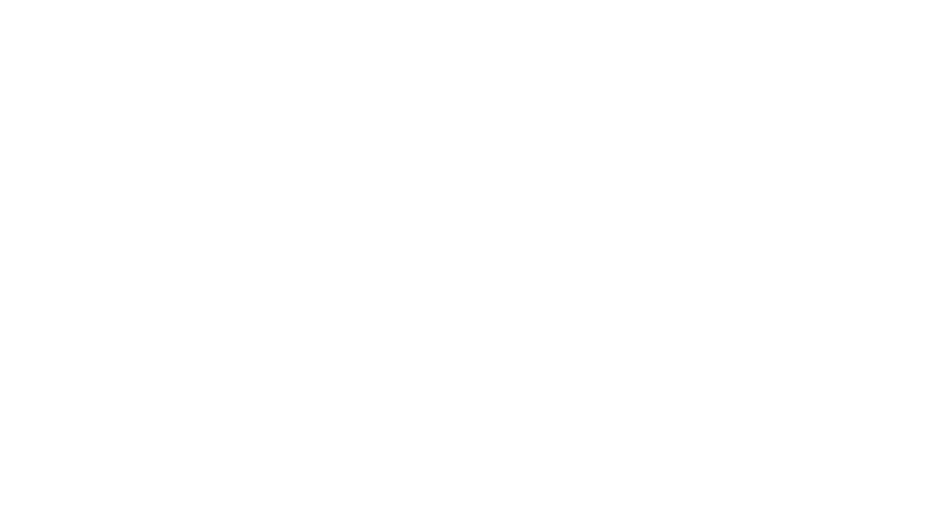

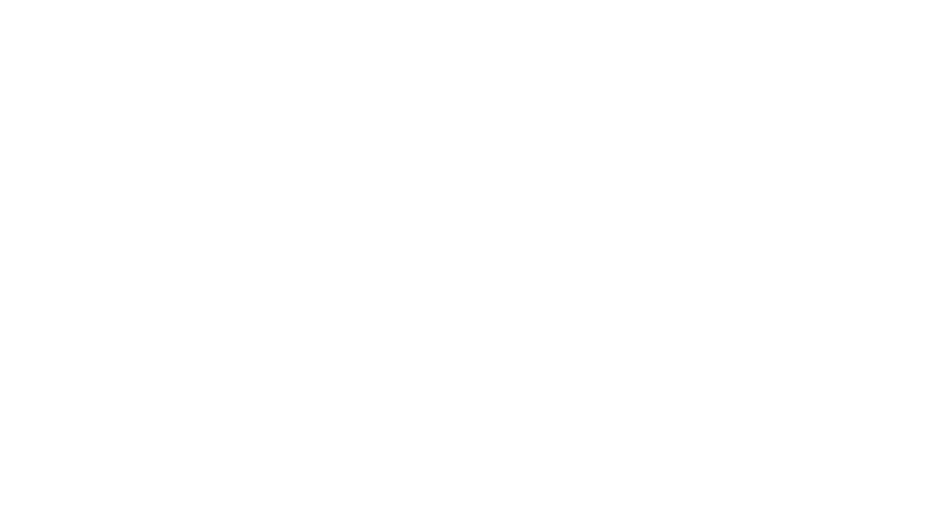

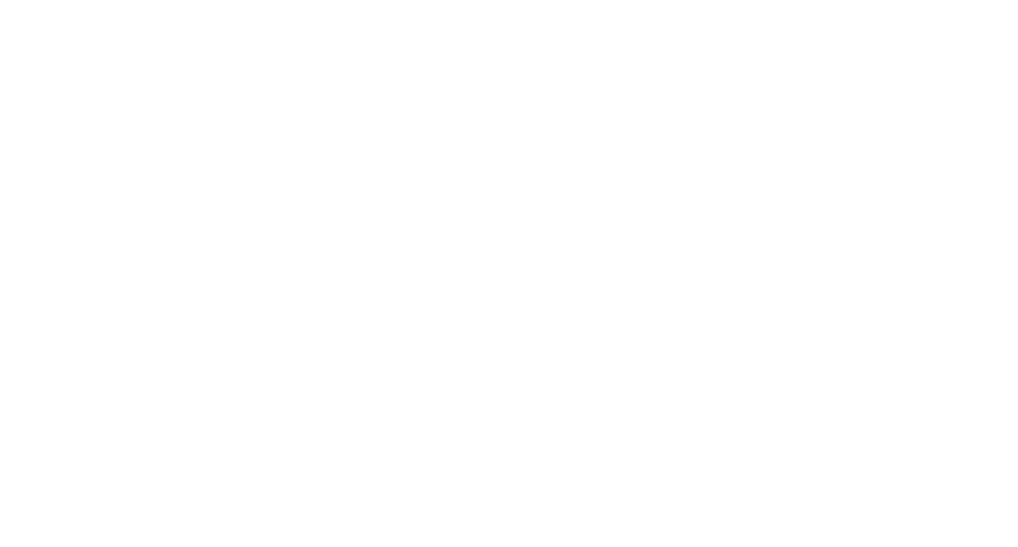

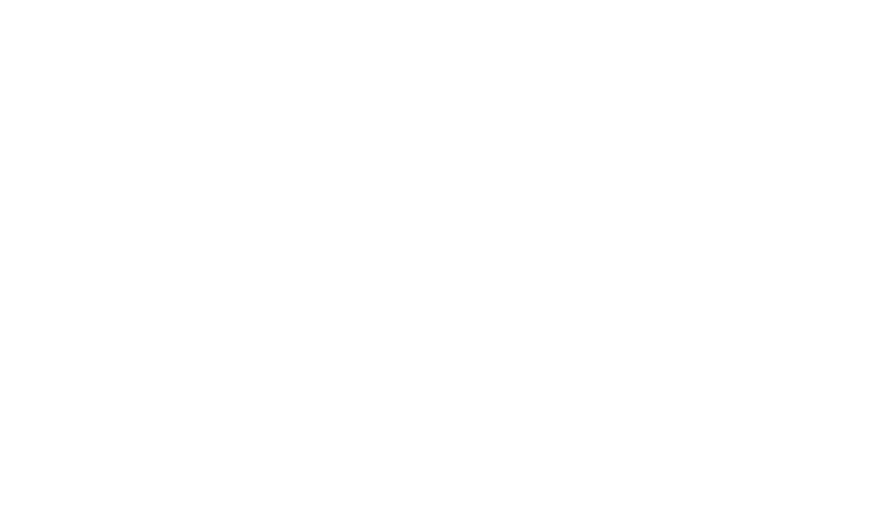

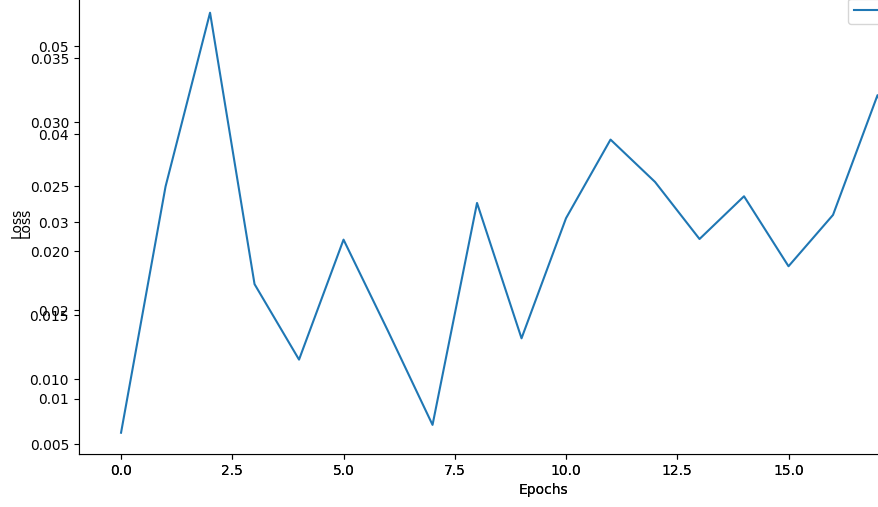

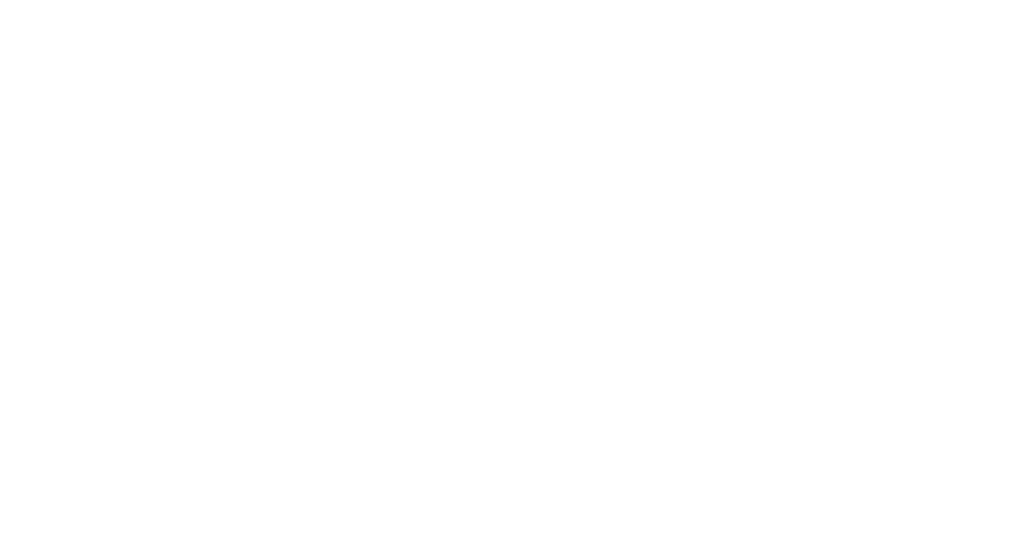

 3/48 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step  

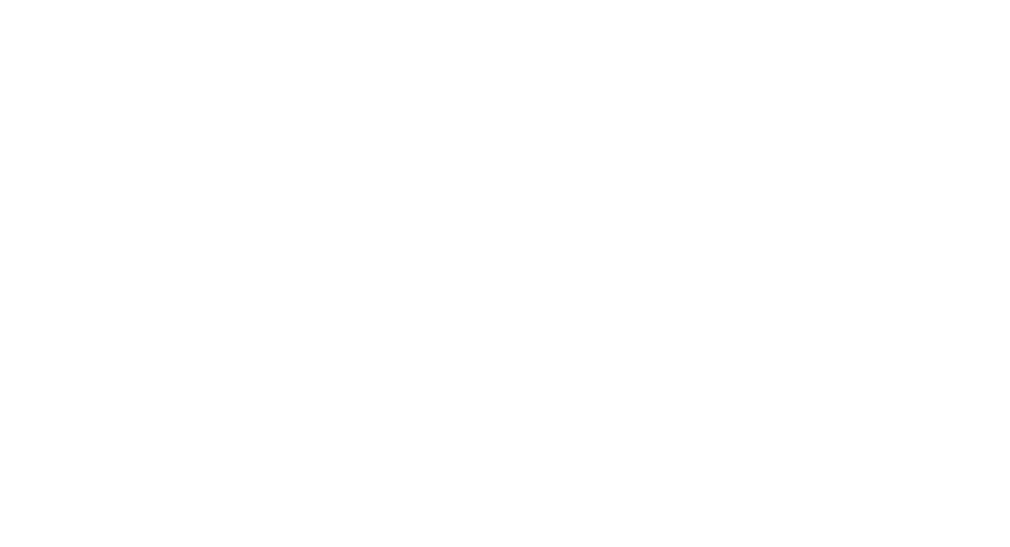

 3/48 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step  

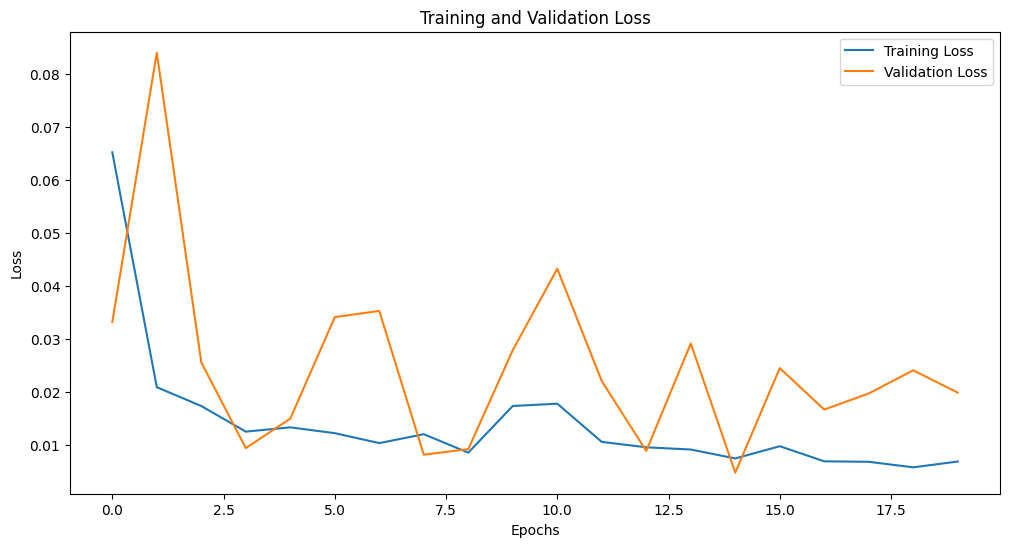

32/48 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step

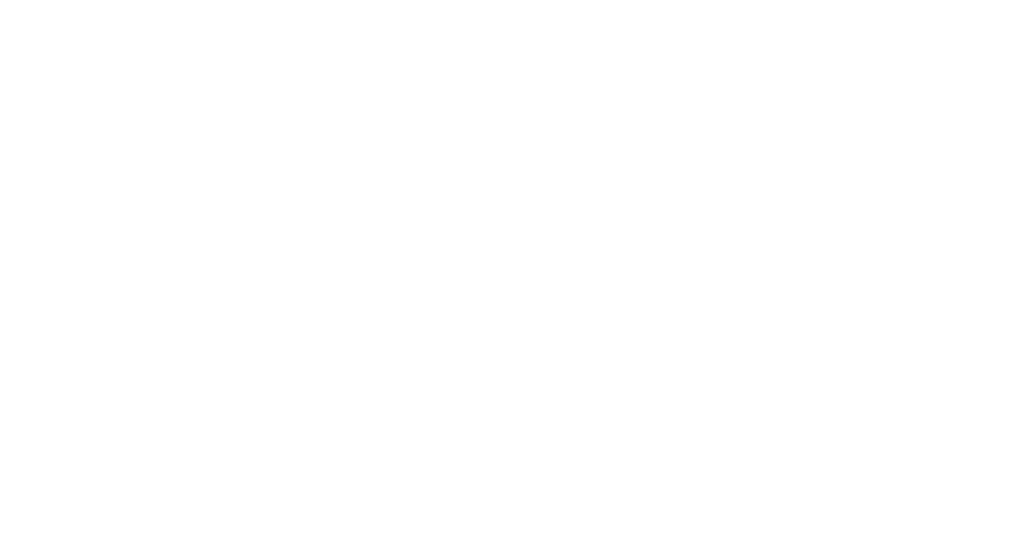

45/48 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step

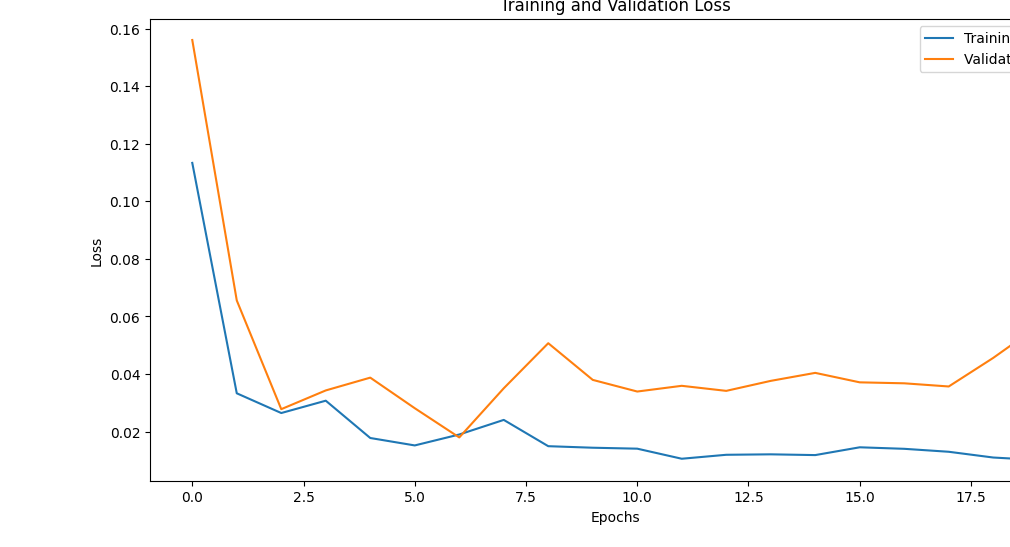

48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step
19/48 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/stepShape of df_scaled before inverse scaling: (1589, 7)
Shape of predictions: (1529, 1)
22/48 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/stepShape of df_scaled before inverse scaling: (1587, 7)
Shape of predictions: (1527, 1)
27/48 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step

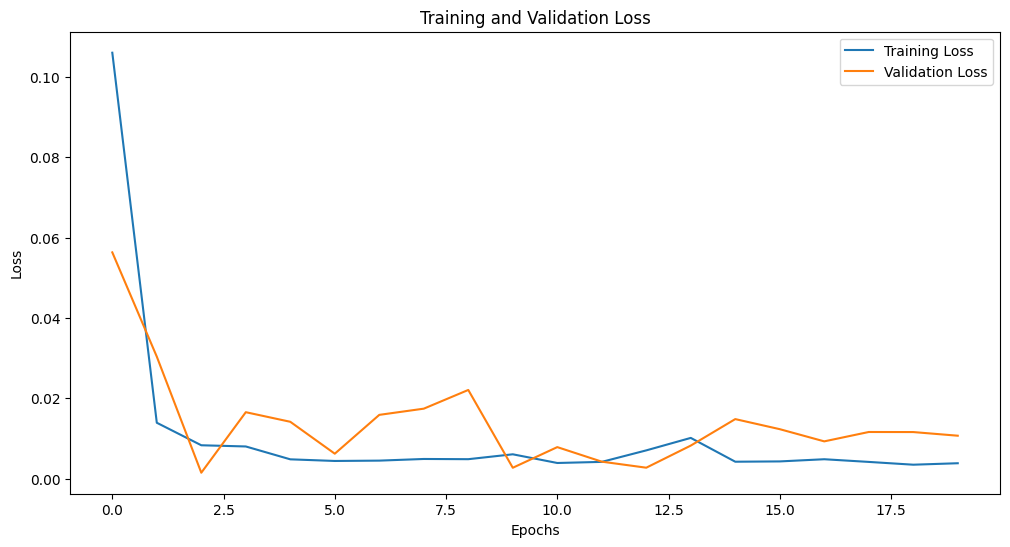

48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step
29/48 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/stepShape of df_scaled before inverse scaling: (1587, 7)
Shape of predictions: (1527, 1)
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step
Shape of df_scaled before inverse scaling: (1587, 7)
Shape of predictions: (1527, 1)
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step
Shape of df_scaled before inverse scaling: (1589, 7)
Shape of predictions: (1529, 1)


In [5]:
# Create directories for models and plots
os.makedirs('models', exist_ok=True)
os.makedirs('plots', exist_ok=True)

# Use ThreadPoolExecutor to process multiple stocks in parallel
seq_length = 60
fig_paths = []

with ThreadPoolExecutor(max_workers=5) as executor:
    futures = [executor.submit(process_stock, stock, seq_length) for stock in dow_jones_stocks]
    for future in as_completed(futures):
        fig_path = future.result()
        if fig_path:
            fig_paths.append(fig_path)

In [6]:
top_10_models = evaluate_pretrained_models(dow_jones_stocks, seq_length)
top_10_models

48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step


C:\Users\Asad\AppData\Local\Temp\ipykernel_23148\2523027085.py:211: RuntimeWarning: divide by zero encountered in divide
  return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


C:\Users\Asad\AppData\Local\Temp\ipykernel_23148\2523027085.py:211: RuntimeWarning: divide by zero encountered in divide
  return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


C:\Users\Asad\AppData\Local\Temp\ipykernel_23148\2523027085.py:211: RuntimeWarning: divide by zero encountered in divide
  return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


C:\Users\Asad\AppData\Local\Temp\ipykernel_23148\2523027085.py:211: RuntimeWarning: divide by zero encountered in divide
  return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


C:\Users\Asad\AppData\Local\Temp\ipykernel_23148\2523027085.py:211: RuntimeWarning: divide by zero encountered in divide
  return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


[('AAPL', inf), ('MSFT', inf), ('IBM', inf), ('JNJ', inf), ('PG', inf)]

In [ ]:
best_stock_models = [stock for stock in top_10_models if stock[1] < 0.1]
best_counters = [stock[0] for stock in best_stock_models]
best_counters

# Trade using the models with RMSE less than 0.1

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import load_model
import joblib
import alpaca_trade_api as tradeapi
import time

def fetch_live_data(stock_code, interval='1m', period='1d'):
    ticker = yf.Ticker(stock_code)
    data = ticker.history(interval=interval, period=period)
    if data.empty:
        raise ValueError(f"No data found for {stock_code} with the given parameters.")
    return data

def predict_future_prices(model, scaler, df, seq_length):
    df = add_indicators(df)
    feature_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
    scaled_features = scaler.transform(df[feature_columns])
    df_scaled = pd.DataFrame(scaled_features, columns=feature_columns, index=df.index)
    X, _ = create_sequences(df_scaled, seq_length)
    predictions = model.predict(X)

    dummy_combined = np.zeros((predictions.shape[0], df_scaled.shape[1]))
    dummy_combined[:, 3] = predictions.squeeze()
    inverse_transformed = scaler.inverse_transform(dummy_combined)
    inv_pred_df = pd.DataFrame(inverse_transformed[:, 3], 
                               columns=['Predicted_Close'], 
                               index=df.index[seq_length:])
    return inv_pred_df

def trade_logic(stock_code, model, scaler, seq_length):
    while True:
        df = fetch_live_data(stock_code)
        predictions = predict_future_prices(model, scaler, df, seq_length)

        current_price = df.iloc[-1]['Close']
        predicted_price = predictions.iloc[-1]['Predicted_Close']

        if predicted_price > current_price * 1.02:  # Buy signal
            api.submit_order(
                symbol=stock_code,
                qty=10,  # Define quantity
                side='buy',
                type='market',
                time_in_force='gtc'
            )
            print(f"Buying {stock_code} at {current_price}")
        elif predicted_price < current_price * 0.98:  # Sell signal
            api.submit_order(
                symbol=stock_code,
                qty=10,  # Define quantity
                side='sell',
                type='market',
                time_in_force='gtc'
            )
            print(f"Selling {stock_code} at {current_price}")
        
        time.sleep(60)  # Wait a minute before the next iteration

def main_trading_loop(stocks, seq_length):
    for stock_code in stocks:
        try:
            model_path = f'models/model_{stock_code}.keras'
            scaler_path = f'scalers/scaler_{stock_code}.pkl'
            model = load_model(model_path)
            scaler = joblib.load(scaler_path)
            
            print(f"Starting trading for {stock_code}")
            trade_logic(stock_code, model, scaler, seq_length)
        except Exception as e:
            print(f"Error trading {stock_code}: {e}")

# List of stocks with low RMSE
stocks = best_counters # Replace with your selected stocks

main_trading_loop(stocks, seq_length=60)  # Adjust sequence length as needed
